# 03. Сколько на самом деле дает платное продвижение объявления

Продавец может купить пакет "В топ на 7 дней": объявление поднимается в выдаче. Вопрос от бизнеса: **сколько дополнительных просмотров и контактов получает объявление за счет продвижения?** От ответа зависят цена пакета и то, как мы его продаем ("+X% просмотров").

A/B тест здесь не провести (нельзя продать услугу и не оказать ее), поэтому оцениваем эффект на наблюдательных данных. Главная сложность — **самоотбор**: продвижение покупают не случайно. План:
1. понять, кто и когда покупает продвижение;
2. посмотреть, насколько врут наивные оценки;
3. оценить эффект через matching + difference-in-differences и проверить параллельность трендов (event study).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

plt.rcParams.update({
    "figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
})
DATA, FIG = "../data", "../reports/figures"

listings = pd.read_parquet(f"{DATA}/listings.parquet")
ld = pd.read_parquet(f"{DATA}/listing_daily.parquet")
promos = pd.read_parquet(f"{DATA}/promotions.parquet")
ld["dt"] = pd.to_datetime(ld["dt"])
listings["created_dt"] = pd.to_datetime(listings["created_dt"])

# переводим панель в матрицы listing x day — так все окна считаются векторно
days = pd.date_range("2025-06-01", "2025-08-31")
T = len(days)
lid = pd.Index(listings["listing_id"])
r, c = lid.get_indexer(ld["listing_id"]), (ld["dt"] - days[0]).dt.days.values
V = np.zeros((len(lid), T)); V[r, c] = ld["views"]
K = np.zeros((len(lid), T)); K[r, c] = ld["contacts"]
A = np.zeros((len(lid), T), dtype=bool); A[r, c] = True

promo_day = np.full(len(lid), -1)
promo_day[lid.get_indexer(promos["listing_id"])] = (pd.to_datetime(promos["promo_start_dt"]) - days[0]).dt.days
created = (listings["created_dt"] - days[0]).dt.days.values

print(f"объявлений: {len(lid)}, из них продвигались: {(promo_day >= 0).sum()} ({(promo_day >= 0).mean():.1%})")

объявлений: 22000, из них продвигались: 3583 (16.3%)


## 1. Кто и когда покупает продвижение

Модель склонности: логистическая регрессия на панели "объявление-день". Наблюдение — день, когда объявление активно, ему 4+ дня и его еще не продвигали; таргет — купили ли продвижение в этот день. Кроме статичных признаков, добавляю динамику просмотров: отношение просмотров за последние 3 дня к просмотрам за дни -10..-4 (`dip`).

In [2]:
cs = np.concatenate([np.zeros((len(lid), 1)), np.cumsum(V, axis=1)], axis=1)
def window_mean(t, a, b):
    # среднее просмотров в днях [t+a, t+b] (a, b < 0), t — вектор дней
    return (cs[:, t + b + 1] - cs[:, t + a]) / (b - a + 1)

panel = []
for t in range(10, T):
    age = t - created
    ok = A[:, t] & (age >= 10) & ((promo_day == -1) | (promo_day >= t)) & A[:, t - 10]
    i = np.flatnonzero(ok)
    near = window_mean(t, -3, -1)[i]
    far = window_mean(t, -10, -4)[i]
    panel.append(pd.DataFrame({"i": i, "t": t, "age": age[i], "promo": (promo_day[i] == t).astype(int),
                               "dip": np.log((near + 1) / (far + 1)), "log_views_far": np.log1p(far)}))
panel = pd.concat(panel, ignore_index=True)
panel = panel.join(listings[["owner_type", "deal_type", "city", "photos_cnt"]], on="i")
print(f"наблюдений: {len(panel):,}, покупок: {panel['promo'].sum()}")

logit = smf.logit("promo ~ C(owner_type, Treatment('owner')) + deal_type + dip + log_views_far + np.log(age) + photos_cnt",
                  data=panel).fit(disp=0)
coef = pd.DataFrame({"odds_ratio": np.exp(logit.params), "p_value": logit.pvalues})
coef.round(3)

наблюдений: 254,319, покупок: 2667


,odds_ratio,p_value
Intercept,0.008,0.000
"C(owner_type, Treatment('owner'))[T.agent]",3.249,0.000
"C(owner_type, Treatment('owner'))[T.developer]",5.462,0.000
deal_type[T.sale],0.906,0.023
dip,0.417,0.000
log_views_far,0.574,0.000
np.log(age),1.103,0.008
photos_cnt,1.026,0.000


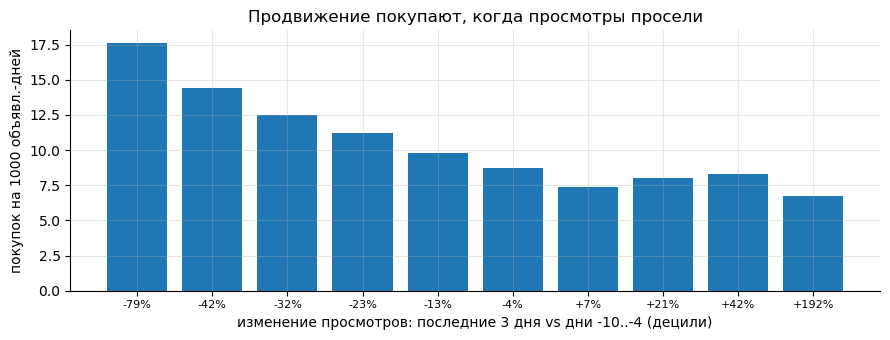

In [3]:
# как выглядит просадка: средние просмотры перед покупкой у тех, кто купил, vs у похожих по возрасту объявлений
panel["dip_bin"] = pd.qcut(panel["dip"], 10, duplicates="drop")
rate = panel.groupby("dip_bin", observed=True)["promo"].mean() * 1000

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(range(len(rate)), rate.values, color="C0")
ax.set_xticks(range(len(rate)))
ax.set_xticklabels([f"{np.exp(b.mid) - 1:+.0%}" for b in rate.index], fontsize=8)
ax.set_xlabel("изменение просмотров: последние 3 дня vs дни -10..-4 (децили)")
ax.set_ylabel("покупок на 1000 объявл.-дней")
ax.set_title("Продвижение покупают, когда просмотры просели")
plt.tight_layout()
plt.savefig(f"{FIG}/03_who_buys.png", dpi=120)

Две вещи, которые ломают наивные оценки:
- **агенты и застройщики** покупают продвижение в разы чаще собственников;
- продвижение покупают **после просадки просмотров**. Но просадки во многом временные — просмотры вернулись бы и без продвижения (возврат к среднему). Значит, сравнение "до/после" припишет продвижению и этот естественный возврат.

## 2. Наивные оценки

In [4]:
pre_w, post_w = (-10, -1), (0, 6)
rel = np.arange(pre_w[0], post_w[1] + 1)

def eligible_treated():
    out = []
    for i in np.flatnonzero(promo_day >= 0):
        s = promo_day[i]
        if s + pre_w[0] >= 0 and s + post_w[1] < T and A[i, s + pre_w[0]: s + post_w[1] + 1].all():
            out.append(i)
    return np.array(out)

tr = eligible_treated()
print(f"продвижений с полным окном [-10; +6]: {len(tr)}")

naive = {}
# 1) сравнение средних: объявления в дни продвижения vs все остальные активные дни
on_promo = np.zeros_like(A)
for i in np.flatnonzero(promo_day >= 0):
    on_promo[i, promo_day[i]: promo_day[i] + 7] = True
on_promo &= A
naive["в дни продвижения vs все остальные"] = V[on_promo].mean() / V[A & ~on_promo].mean() - 1

# 2) до/после: 3 дня до покупки vs 7 дней после
def win_sum(M, ids, a, b):
    return np.array([M[i, promo_day[i] + a: promo_day[i] + b + 1].mean() for i in ids])
naive["до/после (3 дня до vs 7 дней после)"] = win_sum(V, tr, 0, 6).mean() / win_sum(V, tr, -3, -1).mean() - 1
naive["до/после (10 дней до vs 7 дней после)"] = win_sum(V, tr, 0, 6).mean() / win_sum(V, tr, -10, -1).mean() - 1
pd.Series(naive, name="эффект на просмотры").map("{:+.1%}".format).to_frame()

продвижений с полным окном [-10; +6]: 2059


,эффект на просмотры
в дни продвижения vs все остальные,+19.2%
до/после (3 дня до vs 7 дней после),+59.6%
до/после (10 дней до vs 7 дней после),+34.8%


Разброс огромный, и ни одной из этих оценок нельзя верить: первая смешивает разные типы объявлений и разный возраст, вторая и третья — эффект продвижения, затухание просмотров с возрастом объявления и возврат после просадки.

## 3. Matching + difference-in-differences

Для каждого продвинутого объявления ищу "двойника" среди объявлений, которые в это же время не продвигались:
- точное совпадение по городу, типу сделки и типу продавца;
- ближайший сосед по возрасту объявления и по просмотрам в дни -10..-4 и -3..-1 (т.е. двойник тоже должен был "просесть").

Дальше DiD: `(просмотры_после / просмотры_до)` у продвинутых делим на то же отношение у двойников. Общие для обоих факторы (возраст, сезонность, день недели, возврат после просадки) сокращаются.

In [5]:
def match(treated, features):
    keys = listings[["city", "deal_type", "owner_type"]].astype(str).agg("|".join, axis=1).values
    pairs = []
    for s in np.unique(promo_day[treated]):
        # контроль: активен все окно и не продвигается в окне (и не продвигался прямо перед ним)
        ok = A[:, s + pre_w[0]: s + post_w[1] + 1].all(axis=1)
        ok &= (promo_day == -1) | (promo_day > s + post_w[1]) | (promo_day + 7 <= s + pre_w[0])
        X = np.column_stack([f(s) for f in features.values()])
        mu, sd = X[ok].mean(0), X[ok].std(0) + 1e-9
        Z = (X - mu) / sd
        for i in treated[promo_day[treated] == s]:
            cand = np.flatnonzero(ok & (keys == keys[i]))
            if len(cand) == 0:
                continue
            j = cand[np.argmin(((Z[cand] - Z[i]) ** 2).sum(1))]
            pairs.append((i, j, s))
    return pd.DataFrame(pairs, columns=["treated", "control", "s"])

feat_full = {
    "age": lambda s: np.log1p(np.maximum(s - created, 0)),
    "far": lambda s: np.log1p(window_mean(s, -10, -4)),
    "near": lambda s: np.log1p(window_mean(s, -3, -1)),
}
feat_far_only = {k: feat_full[k] for k in ("age", "far")}

pairs = match(tr, feat_full)
pairs_far = match(tr, feat_far_only)
print(f"пар: {len(pairs)} (полный матчинг), {len(pairs_far)} (без учета просадки)")

пар: 2058 (полный матчинг), 2058 (без учета просадки)


In [6]:
def window_matrix(M, ids, starts):
    return np.stack([M[i, s + rel[0]: s + rel[-1] + 1] for i, s in zip(ids, starts)])

def balance(pairs):
    out = {}
    for name, f in feat_full.items():
        xt = np.array([f(s)[i] for i, s in zip(pairs["treated"], pairs["s"])])
        xc = np.array([f(s)[j] for j, s in zip(pairs["control"], pairs["s"])])
        out[name] = (xt.mean() - xc.mean()) / np.sqrt((xt.var() + xc.var()) / 2)
    return pd.Series(out)

# баланс до матчинга: против случайных объявлений, активных в тот же день
rng = np.random.default_rng(0)
rand_pairs = pd.DataFrame({"treated": pairs["treated"], "s": pairs["s"]})
rand_pairs["control"] = [rng.choice(np.flatnonzero(A[:, s + pre_w[0]: s + post_w[1] + 1].all(1))) for s in pairs["s"]]
pd.DataFrame({"до матчинга": balance(rand_pairs), "без учета просадки": balance(pairs_far),
              "полный матчинг": balance(pairs)}).round(3).rename_axis("стандартизованная разница")

,до матчинга,без учета просадки,полный матчинг
стандартизованная разница,,,
age,-0.134,-0.008,-0.017
far,-0.097,-0.014,0.007
near,-0.331,-0.301,-0.050


In [7]:
def did(pairs, M, n_boot=1000, seed=0):
    Wt = window_matrix(M, pairs["treated"], pairs["s"])
    Wc = window_matrix(M, pairs["control"], pairs["s"])
    pre, post = rel < 0, rel >= 0
    def est(idx):
        t, c = Wt[idx], Wc[idx]
        return (t[:, post].sum() / t[:, pre].sum()) / (c[:, post].sum() / c[:, pre].sum()) - 1
    point = est(np.arange(len(pairs)))
    rng = np.random.default_rng(seed)
    boots = [est(rng.integers(0, len(pairs), len(pairs))) for _ in range(n_boot)]
    lo, hi = np.quantile(boots, [0.025, 0.975])
    return point, lo, hi, Wt, Wc

res = {}
for name, p in [("DiD, случайные контрольные объявления", rand_pairs),
                ("DiD, матчинг без учета просадки", pairs_far), ("DiD, полный матчинг", pairs)]:
    for metric, M in [("просмотры", V), ("контакты", K)]:
        point, lo, hi, *_ = did(p, M)
        res[(name, metric)] = {"эффект": point, "ci_low": lo, "ci_high": hi}
res = pd.DataFrame(res).T
res.style.format("{:+.1%}")

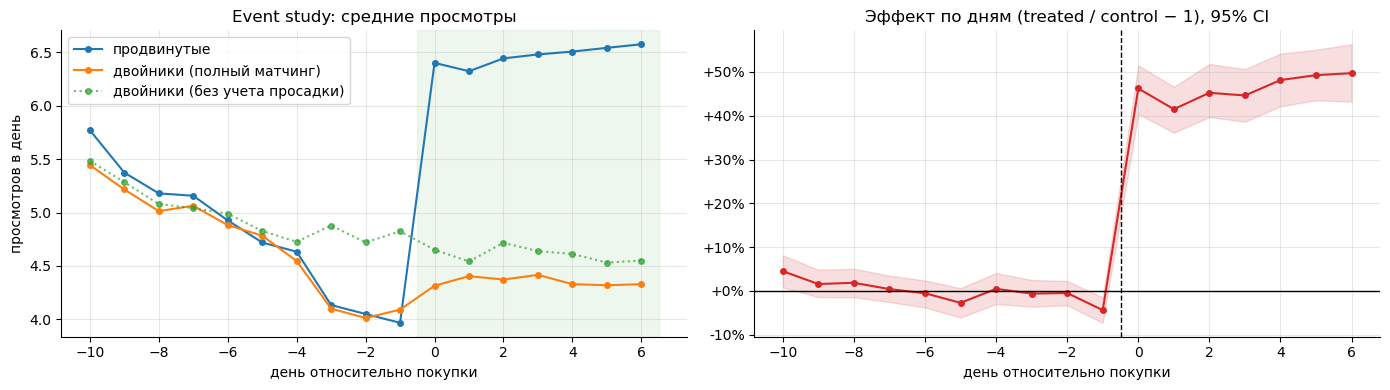

In [8]:
_, _, _, Wt, Wc = did(pairs, V, n_boot=1)
_, _, _, Wt_f, Wc_f = did(pairs_far, V, n_boot=1)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(rel, Wt.mean(0), marker="o", ms=4, label="продвинутые")
ax[0].plot(rel, Wc.mean(0), marker="o", ms=4, label="двойники (полный матчинг)")
ax[0].plot(rel, Wc_f.mean(0), marker="o", ms=4, ls=":", alpha=0.7, label="двойники (без учета просадки)")
ax[0].axvspan(-0.5, 6.5, color="C2", alpha=0.08)
ax[0].set_xlabel("день относительно покупки"); ax[0].set_ylabel("просмотров в день")
for a in ax:
    a.xaxis.set_major_locator(plt.MultipleLocator(2))
ax[0].set_title("Event study: средние просмотры")
ax[0].legend()

# по дням: отношение treated / control, нормированное на предпериод
ratio = Wt.mean(0) / Wc.mean(0)
ratio = ratio / ratio[rel < 0].mean() - 1
boot = []
rng = np.random.default_rng(1)
for _ in range(500):
    idx = rng.integers(0, len(Wt), len(Wt))
    rr = Wt[idx].mean(0) / Wc[idx].mean(0)
    boot.append(rr / rr[rel < 0].mean() - 1)
lo, hi = np.quantile(boot, [0.025, 0.975], axis=0)
ax[1].plot(rel, ratio, marker="o", ms=4, color="C3")
ax[1].fill_between(rel, lo, hi, color="C3", alpha=0.15)
ax[1].axhline(0, color="k", lw=1)
ax[1].axvline(-0.5, color="k", ls="--", lw=1)
ax[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:+.0%}"))
ax[1].set_xlabel("день относительно покупки")
ax[1].set_title("Эффект по дням (treated / control − 1), 95% CI")
plt.tight_layout()
plt.savefig(f"{FIG}/03_event_study.png", dpi=120)

## 4. Проверка: плацебо

Если метод работает, то на "фальшивой" дате покупки он должен показывать ноль. Сдвигаю дату покупки на 14 дней назад: окно [-10; +6] вокруг фальшивой даты целиком приходится на время до реального продвижения. Для этого нужны объявления, которые жили достаточно долго, поэтому пар будет меньше.

In [9]:
PLACEBO_SHIFT = 14
tr_pl = np.array([i for i in tr if promo_day[i] - PLACEBO_SHIFT + pre_w[0] >= 0
                  and A[i, promo_day[i] - PLACEBO_SHIFT + pre_w[0]: promo_day[i]].all()])
promo_day_backup = promo_day.copy()
promo_day[tr_pl] = promo_day[tr_pl] - PLACEBO_SHIFT  # временно подменяем дату
pairs_pl = match(tr_pl, feat_full)
pl_point, pl_lo, pl_hi, *_ = did(pairs_pl, V)
promo_day = promo_day_backup
print(f"плацебо: пар {len(pairs_pl)}, 'эффект' = {pl_point:+.1%}, 95% CI [{pl_lo:+.1%}; {pl_hi:+.1%}]")

плацебо: пар 912, 'эффект' = -3.9%, 95% CI [-8.1%; +0.3%]


Что это значит в абсолютных числах для одного объявления за 7 дней продвижения:

In [10]:
post = rel >= 0
Wt_k = window_matrix(K, pairs["treated"], pairs["s"])
for metric, W in [("просмотры", Wt), ("контакты", Wt_k)]:
    eff = res.loc[("DiD, полный матчинг", metric), "эффект"]
    total = W[:, post].sum(1).mean()
    print(f"{metric}: за 7 дней в среднем {total:.1f}, из них за счет продвижения ~{total - total / (1 + eff):.1f}")

просмотры: за 7 дней в среднем 45.3, из них за счет продвижения ~14.3
контакты: за 7 дней в среднем 2.3, из них за счет продвижения ~0.5


## 5. Вывод

**Эффект продвижения: +46% просмотров (95% CI [+42%; +50%]) и +30% контактов ([+22%; +39%])** за 7 дней пакета. В абсолютных числах — около +14 просмотров и +0.5 контакта на объявление.

Что важно:
- **Наивные оценки разлетаются от +19% до +60%.** Самая "продающая" цифра (+60%, сравнение с днями прямо перед покупкой) завышена: продвижение покупают после просадки, и часть роста — просто возврат просмотров к норме.
- **Контакты растут слабее просмотров.** Продвижение приводит менее целевой трафик: людей, которые увидели объявление в топе, а не нашли его по своим фильтрам. Обещать продавцу "+46% контактов" нельзя.
- **Устойчивость.** Все три варианта DiD (случайный контроль, матчинг без просадки, полный матчинг) дают близкие оценки — в этих данных DiD с 10-дневным предпериодом сам неплохо гасит смещение. Но параллельные тренды до покупки есть только при полном матчинге (график event study): без учета просадки контрольная группа идет выше в последние дни перед покупкой. Плацебо на сдвинутой дате дает −4% с CI, захватывающим ноль, — небольшой остаточный перекос возможен, но он на порядок меньше эффекта.
- **Ограничения.** Матчинг только по наблюдаемым признакам. Если продавец покупает продвижение, когда, например, снизил цену, эффект снижения цены попадет в оценку. Это стоит проверить, добавив в данные историю изменения цены. И мы оцениваем эффект для тех, кто покупает (ATT); если навязать продвижение всем, эффект может быть другим.

**Что предлагаю продукту:**
1. В интерфейсе покупки показывать честную цифру: "в среднем +40–50% просмотров", а не результат до/после.
2. Предлагать продвижение в момент просадки просмотров (продавцы и так это делают сами) — но измерять результат A/B тестом *рекомендации* (рандомизируем показ предложения, а не саму услугу), это даст чистую оценку эффекта рекомендации на выручку.
3. Т.к. контакты растут хуже просмотров, проверить вариант продвижения с таргетингом только на пользователей, чьи фильтры подходят под объявление.